# OPE 5 - Non-linear Filters for Noise Removal

Apply non-linear filters (median or other rank filters) to remove noise from the images provided in OPE7 and perform analysis. (CO3, CO4)

Enrollment No: 92400133081

## 1. Load images and define functions

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

# Images provided in OPE7 (loaded as grayscale)
man = cv2.imread('man.png', 0)
knee = cv2.imread('knee.png', 0)
city = cv2.imread('city.png', 0)
building = cv2.imread('building.png', 0)

# Alpha trimmed mean filter : sort the window, remove d/2 smallest and d/2 largest values, average the rest
def alpha_trimmed_mean(img, size=5, d=8):
    pad = size // 2
    padded = np.pad(img, pad, mode='reflect')
    windows = sliding_window_view(padded, (size, size)).reshape(img.shape[0], img.shape[1], -1)
    windows = np.sort(windows, axis=2)
    trimmed = windows[:, :, d // 2: size * size - d // 2]
    return trimmed.mean(axis=2).astype(np.uint8)

# Morphological filter : opening followed by closing
def open_close(img, size=3):
    kernel = np.ones((size, size), np.uint8)
    opened = cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel)
    return cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)

# Function to show images in a row
def show(images, titles, size=(14, 4), cmap='gray'):
    plt.figure(figsize=size)
    for i in range(len(images)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(images[i], cmap=cmap, vmin=0, vmax=255)
        plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

## 2. Identify the noise type

man       pixels differing from 5x5 median by more than 80 levels : 1.9 %
knee      pixels differing from 5x5 median by more than 80 levels : 14.8 %
city      pixels differing from 5x5 median by more than 80 levels : 2.2 %
building  pixels differing from 5x5 median by more than 80 levels : 0.0 %
man       strongest Fourier peak / median of spectrum : 94.4
knee      strongest Fourier peak / median of spectrum : 29.2
city      strongest Fourier peak / median of spectrum : 117.8
building  strongest Fourier peak / median of spectrum : 935.1


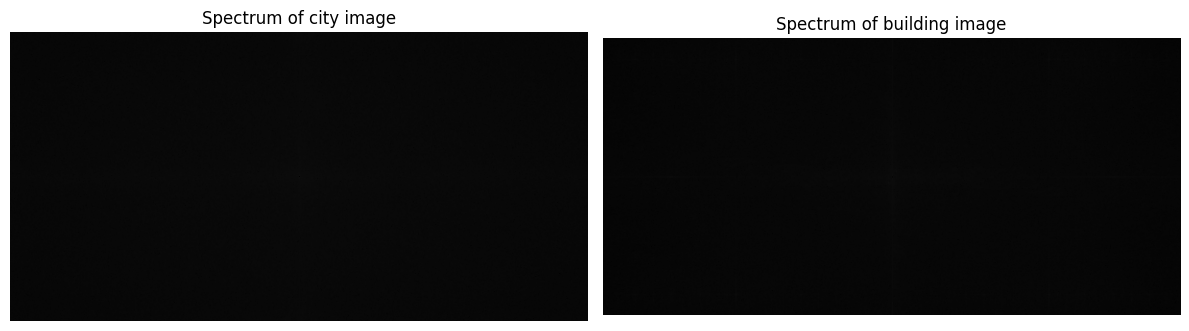

In [2]:
# Impulse (salt and pepper) noise : pixels which differ a lot from the median of their neighbourhood
for name, img in [('man', man), ('knee', knee), ('city', city), ('building', building)]:
    diff = np.abs(img.astype(int) - cv2.medianBlur(img, 5))
    print(f"{name:9s} pixels differing from 5x5 median by more than 80 levels : {100 * np.mean(diff > 80):.1f} %")

# Periodic noise : strong isolated peaks in the Fourier spectrum
def spectrum(img):
    return np.abs(np.fft.fftshift(np.fft.fft2(img - img.mean())))

def peak_ratio(img):
    F = spectrum(img)
    c0, c1 = F.shape[0] // 2, F.shape[1] // 2
    G = F.copy()
    G[c0 - 3:c0 + 4, c1 - 3:c1 + 4] = 0      # ignore the centre (DC) region
    return G.max() / np.median(F)

for name, img in [('man', man), ('knee', knee), ('city', city), ('building', building)]:
    print(f"{name:9s} strongest Fourier peak / median of spectrum : {peak_ratio(img):.1f}")

show([np.log1p(spectrum(city)), np.log1p(spectrum(building))],
     ['Spectrum of city image', 'Spectrum of building image'], size=(12, 4))

## 3. Median filter with different window sizes (salt and pepper noise)

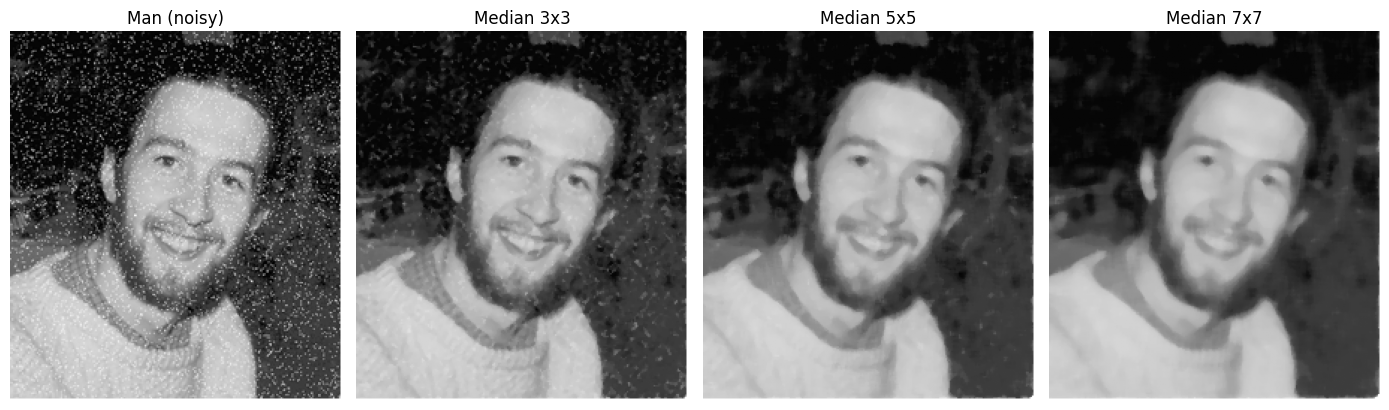

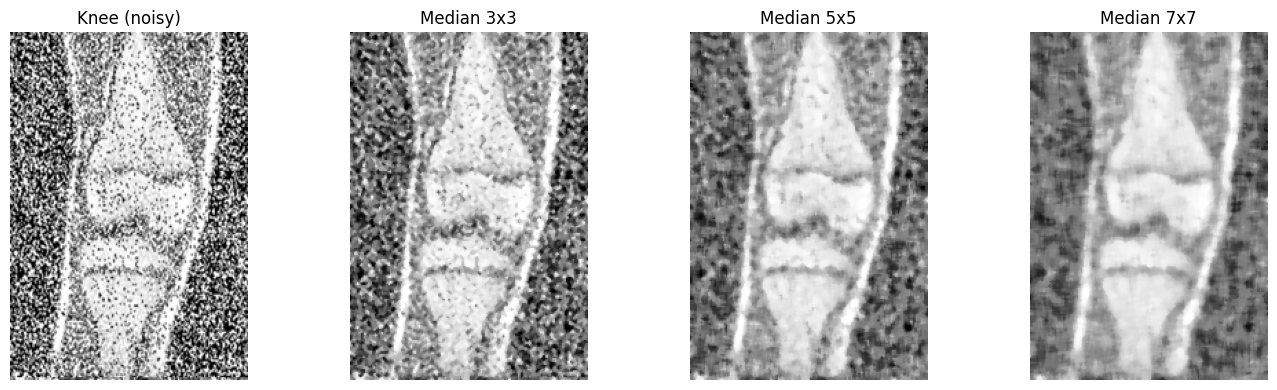

In [3]:
for name, img in [('Man', man), ('Knee', knee)]:
    results = [cv2.medianBlur(img, k) for k in (3, 5, 7)]
    show([img] + results, [name + ' (noisy)', 'Median 3x3', 'Median 5x5', 'Median 7x7'])

## 4. Other non-linear filters (alpha trimmed mean and morphological filter)

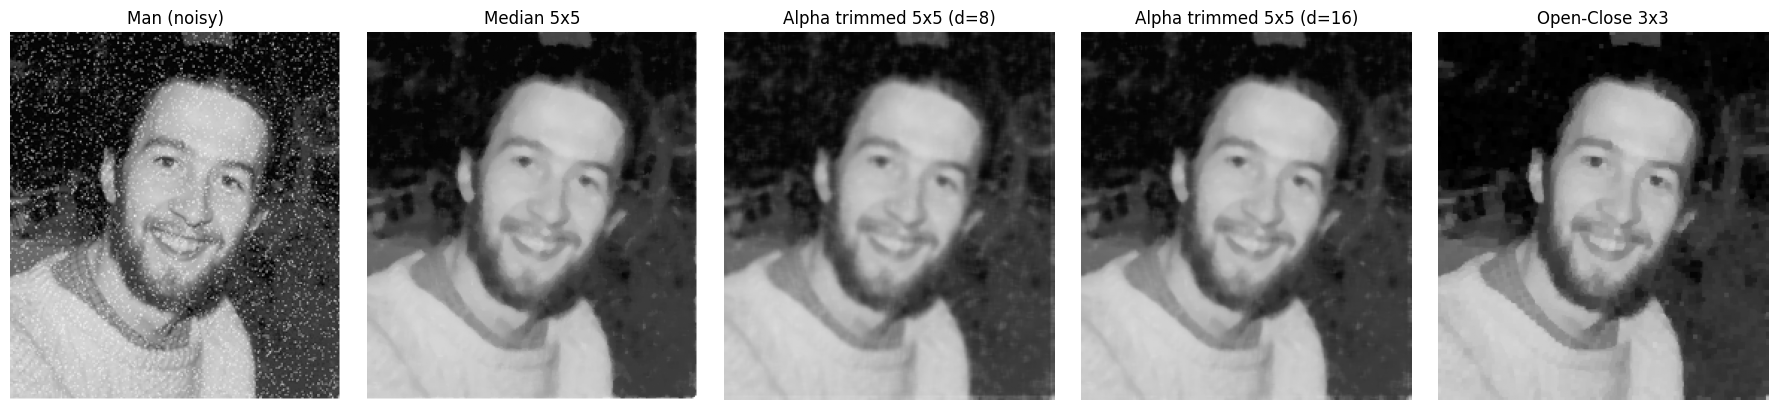

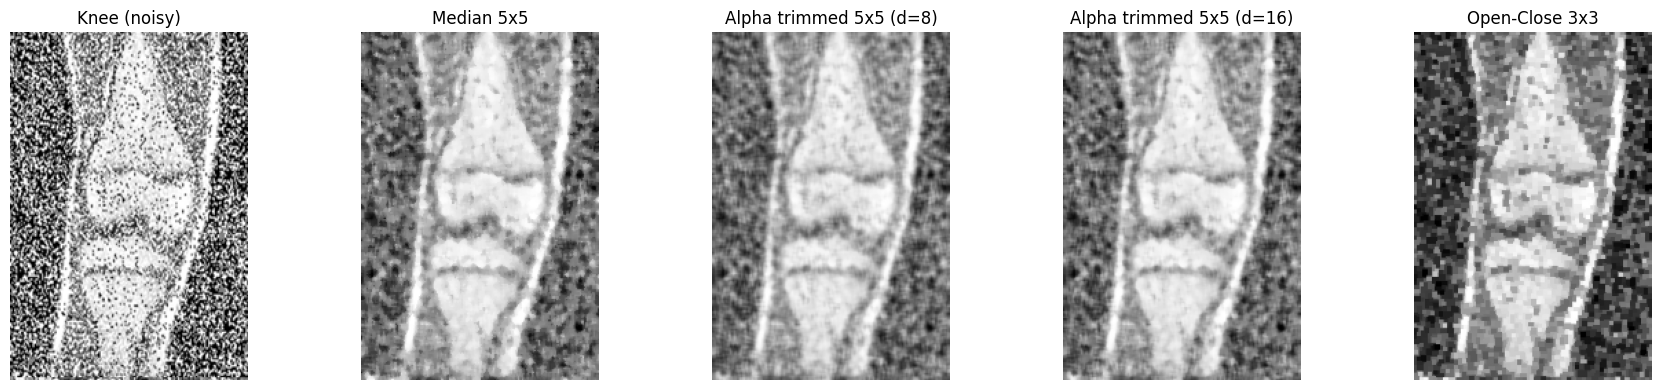

In [4]:
for name, img in [('Man', man), ('Knee', knee)]:
    show([img, cv2.medianBlur(img, 5), alpha_trimmed_mean(img, 5, 8), alpha_trimmed_mean(img, 5, 16), open_close(img, 3)],
         [name + ' (noisy)', 'Median 5x5', 'Alpha trimmed 5x5 (d=8)', 'Alpha trimmed 5x5 (d=16)', 'Open-Close 3x3'], size=(18, 4))

## 5. Median filter on the images with periodic stripe noise

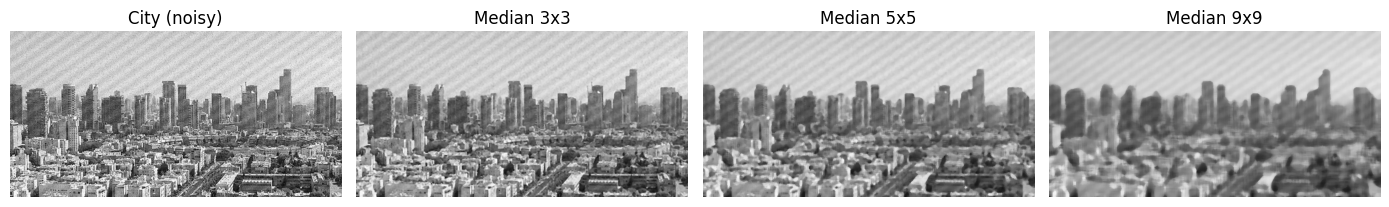

City strongest Fourier peak / median : original = 117.8 , 3x3 = 275.0 , 5x5 = 451.2 , 9x9 = 909.9


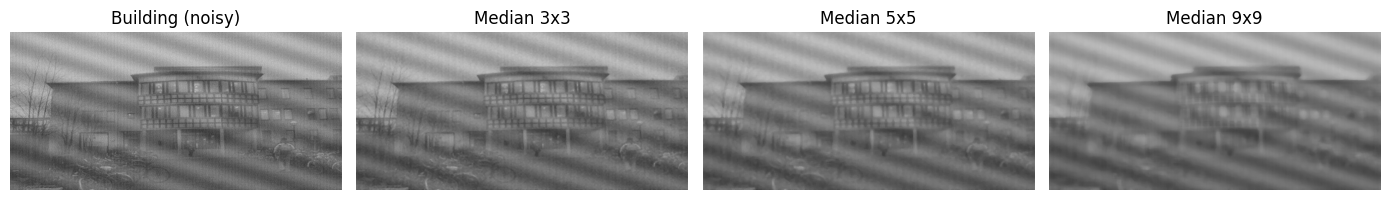

Building strongest Fourier peak / median : original = 935.1 , 3x3 = 1750.1 , 5x5 = 3175.2 , 9x9 = 5326.3


In [5]:
for name, img in [('City', city), ('Building', building)]:
    results = [cv2.medianBlur(img, k) for k in (3, 5, 9)]
    show([img] + results, [name + ' (noisy)', 'Median 3x3', 'Median 5x5', 'Median 9x9'])
    print(name, "strongest Fourier peak / median : original =", round(peak_ratio(img), 1),
          ", 3x3 =", round(peak_ratio(results[0]), 1), ", 5x5 =", round(peak_ratio(results[1]), 1),
          ", 9x9 =", round(peak_ratio(results[2]), 1))

## 6. Controlled experiment on a clean reference image

The provided images do not have a noise free original, so noise is added to a clean image (`clean_reference.png`) and the filters are compared with PSNR (whole image) and edge PSNR (only on the edge pixels).

In [6]:
clean = cv2.imread('clean_reference.png', 0)
rng = np.random.default_rng(1)

# Add noise of different types
def salt_pepper(img, p):
    out = img.copy()
    r = rng.random(img.shape)
    out[r < p / 2] = 0
    out[r > 1 - p / 2] = 255
    return out

def speckle(img, var):
    n = rng.normal(0, np.sqrt(var), img.shape)
    return np.clip(img + img * n, 0, 255).astype(np.uint8)

noisy_images = {
    'Salt & pepper 5%': salt_pepper(clean, 0.05),
    'Salt & pepper 20%': salt_pepper(clean, 0.20),
    'Salt & pepper 40%': salt_pepper(clean, 0.40),
    'Speckle (var 0.1)': speckle(clean, 0.1),
}

# PSNR and edge PSNR
def psnr(a, b):
    return 10 * np.log10(255 ** 2 / np.mean((a.astype(float) - b.astype(float)) ** 2))

edge_mask = cv2.dilate(cv2.Canny(clean, 100, 200), np.ones((3, 3), np.uint8)) > 0

def edge_psnr(a, b):
    return 10 * np.log10(255 ** 2 / np.mean((a[edge_mask].astype(float) - b[edge_mask].astype(float)) ** 2))

filters = {
    'Noisy': lambda x: x,
    'Median 3x3': lambda x: cv2.medianBlur(x, 3),
    'Median 5x5': lambda x: cv2.medianBlur(x, 5),
    'Median 7x7': lambda x: cv2.medianBlur(x, 7),
    'AlphaTrim 5x5': lambda x: alpha_trimmed_mean(x, 5, 8),
    'Open-Close 3x3': lambda x: open_close(x, 3),
}

filtered = {}
print("PSNR (dB)")
print(f"{'':20s}" + "".join(f"{f:>16s}" for f in filters))
for nname, nimg in noisy_images.items():
    row = f"{nname:20s}"
    for fname, f in filters.items():
        filtered[(nname, fname)] = f(nimg)
        row += f"{psnr(clean, filtered[(nname, fname)]):16.2f}"
    print(row)

print()
print("Edge PSNR (dB)")
print(f"{'':20s}" + "".join(f"{f:>16s}" for f in filters))
for nname in noisy_images:
    row = f"{nname:20s}"
    for fname in filters:
        row += f"{edge_psnr(clean, filtered[(nname, fname)]):16.2f}"
    print(row)

PSNR (dB)
                               Noisy      Median 3x3      Median 5x5      Median 7x7   AlphaTrim 5x5  Open-Close 3x3
Salt & pepper 5%               17.81           30.15           27.86           26.27           27.32           26.00


Salt & pepper 20%              11.74           26.90           27.20           25.96           25.52           16.20
Salt & pepper 40%               8.74           18.14           25.42           25.16           19.54            8.22


Speckle (var 0.1)              15.74           21.88           23.92           24.03           24.63           15.67

Edge PSNR (dB)
                               Noisy      Median 3x3      Median 5x5      Median 7x7   AlphaTrim 5x5  Open-Close 3x3
Salt & pepper 5%               18.49           24.93           22.27           20.62           21.66           20.72
Salt & pepper 20%              12.37           22.58           21.54           20.27           20.69           14.30
Salt & pepper 40%               9.34           17.19           20.03           19.43           17.93            8.10
Speckle (var 0.1)              15.46           20.35           20.30           19.38           20.48           14.89


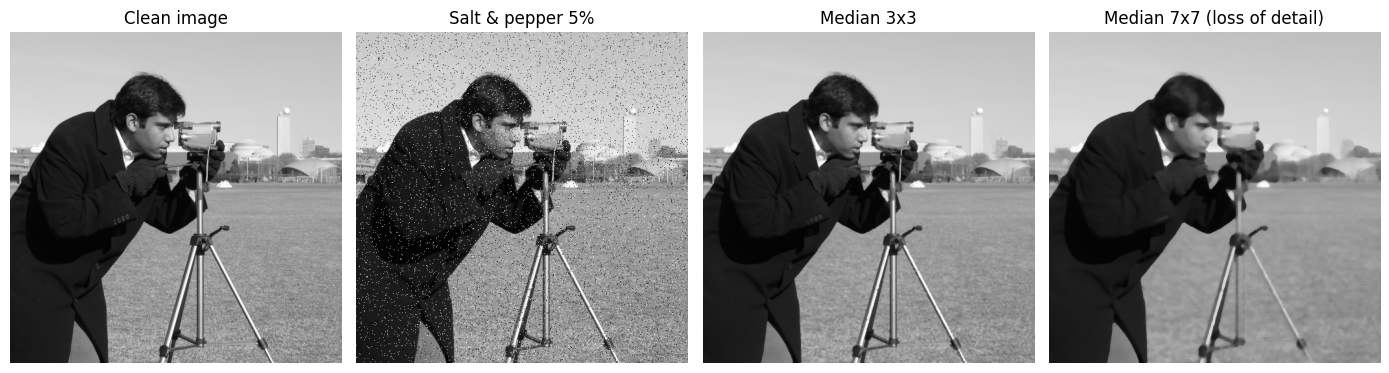

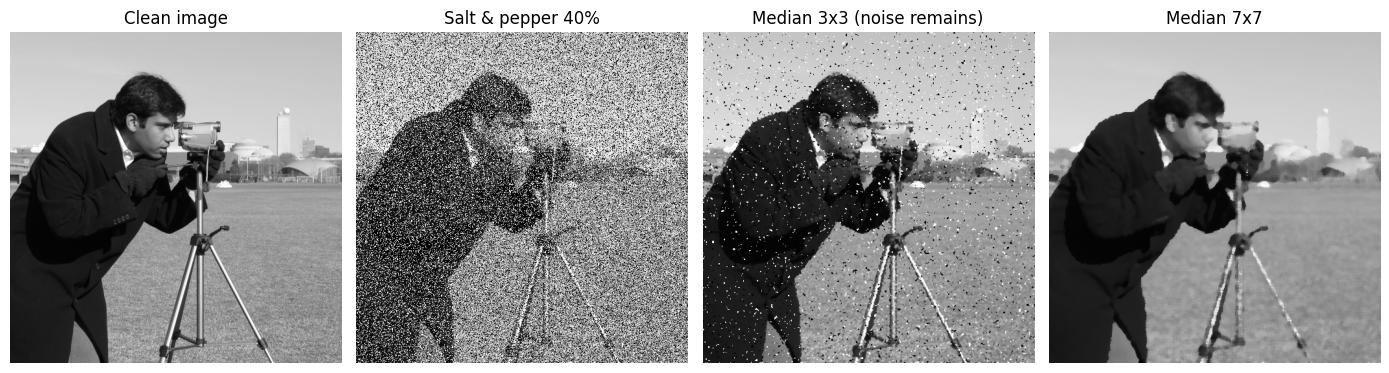

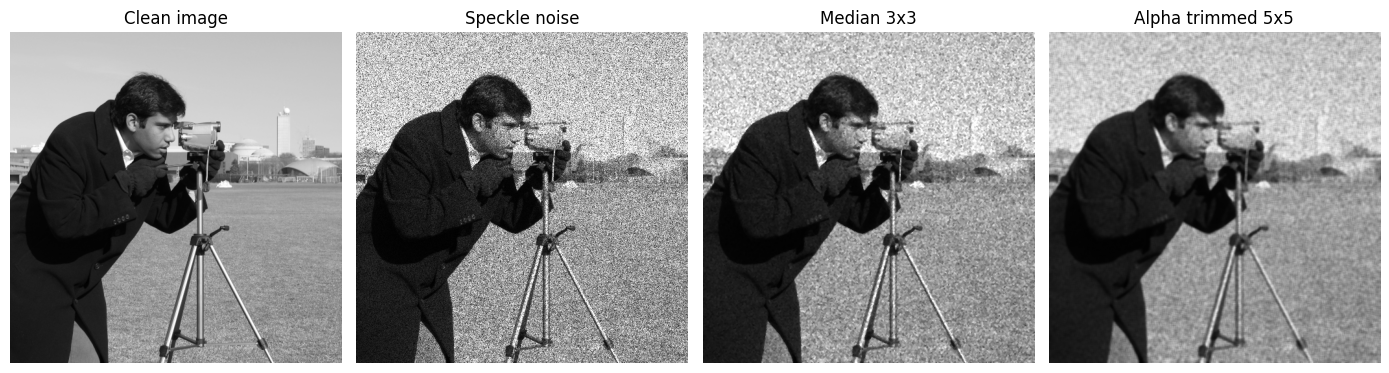

In [7]:
# Visual comparison : best and failure cases
show([clean, noisy_images['Salt & pepper 5%'], filtered[('Salt & pepper 5%', 'Median 3x3')], filtered[('Salt & pepper 5%', 'Median 7x7')]],
     ['Clean image', 'Salt & pepper 5%', 'Median 3x3', 'Median 7x7 (loss of detail)'])

show([clean, noisy_images['Salt & pepper 40%'], filtered[('Salt & pepper 40%', 'Median 3x3')], filtered[('Salt & pepper 40%', 'Median 7x7')]],
     ['Clean image', 'Salt & pepper 40%', 'Median 3x3 (noise remains)', 'Median 7x7'])

show([clean, noisy_images['Speckle (var 0.1)'], filtered[('Speckle (var 0.1)', 'Median 3x3')], filtered[('Speckle (var 0.1)', 'AlphaTrim 5x5')]],
     ['Clean image', 'Speckle noise', 'Median 3x3', 'Alpha trimmed 5x5'])